# Laboratory Exercise 5 – Hidden Markov Models

## Introduction

In this exercise, we will use a Hidden Markov Model (HMM) to represent the difficulty of a sequence of tests and the grades obtained by a student.

The hidden states represent the test difficulty:
- Difficult (D)
- Medium (M)
- Easy (E)

The observations represent the student's grades:
- Very Good (VG)
- Good (G)
- Satisfactory (S)
- Unsatisfactory (U)

We will define the model using the `hmmlearn` library, visualize its state transitions, and determine the most probable sequence of hidden states for a given sequence of grades.

## Part A – Hidden Markov Model

We define three hidden states representing the difficulty of each test: Difficult, Medium, and Easy.

The initial probabilities are equal for all three states.

The transition matrix describes the probability of moving from one difficulty level to another.

The emission matrix describes the probability of obtaining each grade depending on the difficulty of the test.

In [20]:
import numpy as np
from hmmlearn.hmm import CategoricalHMM

# Hidden states and observations
states = ["Difficult", "Medium", "Easy"]
grades = ["VG", "G", "S", "U"]

# Initial probabilities
start_prob = np.array([1/3, 1/3, 1/3])

# Transition probabilities
trans_prob = np.array([
    [0.0, 0.5, 0.5],
    [0.5, 0.25, 0.25],
    [0.5, 0.25, 0.25]
])

# Emission probabilities
emission_prob = np.array([
    [0.1, 0.2, 0.4, 0.3],
    [0.15, 0.25, 0.5, 0.1],
    [0.2, 0.3, 0.4, 0.1]
])

# Create the Hidden Markov Model
model = CategoricalHMM(n_components=3, init_params="")
model.startprob_ = start_prob
model.transmat_ = trans_prob
model.emissionprob_ = emission_prob

print("Hidden Markov Model created successfully!")
print("Transition matrix:")
print(model.transmat_)
print("Emission matrix:")
print(model.emissionprob_)

Hidden Markov Model created successfully!
Transition matrix:
[[0.   0.5  0.5 ]
 [0.5  0.25 0.25]
 [0.5  0.25 0.25]]
Emission matrix:
[[0.1  0.2  0.4  0.3 ]
 [0.15 0.25 0.5  0.1 ]
 [0.2  0.3  0.4  0.1 ]]


### State Transition Diagram

The following graph represents the transition probabilities between the three hidden states: Difficult, Medium, and Easy.

Each arrow shows the probability of moving from one difficulty level to another in the next test.

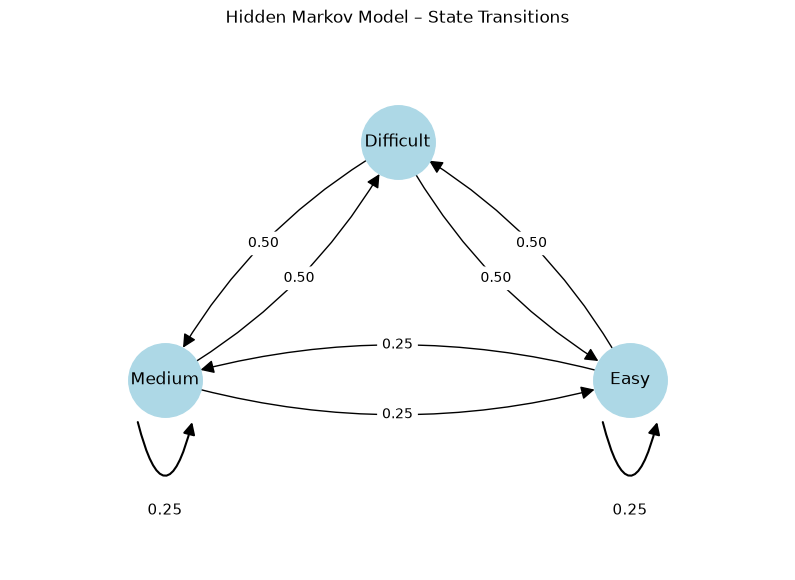

In [21]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# Create the directed graph
G = nx.DiGraph()

for i, state in enumerate(states):
    for j, next_state in enumerate(states):
        if trans_prob[i, j] > 0:
            G.add_edge(state, next_state, weight=trans_prob[i, j])

# Node positions
pos = {
    "Difficult": (0, 1.5),
    "Medium": (-1.5, 0),
    "Easy": (1.5, 0)
}

fig, ax = plt.subplots(figsize=(10, 7))

# Draw nodes and labels
nx.draw_networkx_nodes(G, pos, node_size=2800, node_color="lightblue", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=12, ax=ax)

# Draw transitions between different states
edges = [(u, v) for u, v in G.edges() if u != v]

nx.draw_networkx_edges(
    G, pos,
    edgelist=edges,
    arrows=True,
    arrowsize=20,
    node_size=2800,
    connectionstyle="arc3,rad=0.15",
    ax=ax
)

# Draw probabilities for transitions between different states
edge_labels = {
    (u, v): f"{G[u][v]['weight']:.2f}"
    for u, v in edges
}

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=10,
    rotate=False,
    connectionstyle="arc3,rad=0.15",
    ax=ax
)

# Draw self-loops outside the nodes
for state in ["Medium", "Easy"]:
    x, y = pos[state]

    loop = FancyArrowPatch(
        (x - 0.18, y - 0.25),
        (x + 0.18, y - 0.25),
        connectionstyle="arc3,rad=2.0",
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=1.5,
        color="black"
    )

    ax.add_patch(loop)
    ax.text(x, y - 0.85, "0.25", ha="center", fontsize=11)

plt.title("Hidden Markov Model – State Transitions")
plt.xlim(-2.5, 2.5)
plt.ylim(-1.2, 2.2)
plt.axis("off")
plt.show()

## Part B – Most Probable Sequence of Hidden States

We observe the following sequence of grades:

VG, VG, S, G, G, S, G, G, U, G, G, S

We will use the Viterbi algorithm to determine the most probable sequence of test difficulties corresponding to these observations.

The Viterbi algorithm finds the sequence of hidden states that maximizes the joint probability of the states and the observed grades.

In [22]:
import numpy as np
from hmmlearn import hmm

# Hidden states: test difficulty
states = ["Difficult", "Medium", "Easy"]
id2state = {
    0: "Difficult",
    1: "Medium",
    2: "Easy"
}
# Initial probabilities
start_probs = np.array([1/3, 1/3, 1/3])

# Possible observations: student grades
grades = ["VG", "G", "S", "U"]

# Emission probabilities
emission_probs = np.array([
    [0.1, 0.2, 0.4, 0.3],
    [0.15, 0.25, 0.5, 0.1],
    [0.2, 0.3, 0.4, 0.1]
])

# Transition probabilities
trans_mat = np.array([
    [0.0, 0.5, 0.5],
    [0.5, 0.25, 0.25],
    [0.5, 0.25, 0.25]
])

# Observed grades
observed_grades = [
    "VG", "VG", "S", "G", "G", "S",
    "G", "G", "U", "G", "G", "S"
]

# Convert grades into numerical values
grade2id = {
    "VG": 0,
    "G": 1,
    "S": 2,
    "U": 3
}

# Convert observed grades into a NumPy array of numerical values for the HMM
X = []
for grade in observed_grades:
    X.append([grade2id[grade]])

data = np.array(X)


# Create an HMM with three hidden states and no automatic parameter initialization
model = hmm.CategoricalHMM(
    n_components=len(states),
    init_params=""
)

model.startprob_ = start_probs
model.transmat_ = trans_mat
model.emissionprob_ = emission_probs

# Decode using Viterbi
logprob, received = model.decode(data, algorithm="viterbi")

print("Observed grades:")
print(observed_grades)

print("\nMost probable test difficulties:")
print([id2state[x] for x in received])

print("\nProbability:")
print(np.exp(logprob))

Observed grades:
['VG', 'VG', 'S', 'G', 'G', 'S', 'G', 'G', 'U', 'G', 'G', 'S']

Most probable test difficulties:
['Easy', 'Easy', 'Difficult', 'Easy', 'Difficult', 'Medium', 'Difficult', 'Easy', 'Difficult', 'Easy', 'Difficult', 'Medium']

Probability:
2.109375000000024e-11
